# MNIST Classification (Digits 0, 1, 7)
## 1. Import Libraries & Helper Functions

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from library.gmm import GMM
from library.knn import KNN
from library.lda import LDA
from library.pca import PCA
from library.svm import SVM

def show_clusters(X, y):
    X = X - X.mean(axis=0)

    _, _, V = np.linalg.svd(X, full_matrices=False)
    points = X @ V[:2].T

    for label in np.unique(y):
        mask = y == label
        plt.scatter(points[mask, 0], points[mask, 1], s=2, label=label)

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.show()

def build_confusion_matrix(actual, predicted, labels):
    matrix = np.zeros((len(labels), len(labels)), dtype=int)

    for row, actual_class in enumerate(labels):
        for column, predicted_class in enumerate(labels):
            matrix[row, column] = np.count_nonzero(
                (actual == actual_class) & (predicted == predicted_class)
            )
    return matrix

## 2. Load Data

In [21]:
def load_images(folder):
    images = []
    labels = []
    for digit in [0, 1, 7]:
        digit_folder = f"{folder}/{digit}"
        for filename in sorted(os.listdir(digit_folder)):
            if filename.endswith(".png"):
                with Image.open(f"{digit_folder}/{filename}") as image:
                    pixels = np.array(image.convert("L"), dtype=float)
                    images.append(pixels.ravel() / 255.0)
                    labels.append(digit)
    return np.array(images), np.array(labels)


train_features, train_labels = load_images("./data/mnist/train")
valid_features, valid_labels = load_images("./data/mnist/dev")
test_features, test_labels = load_images("./data/mnist/test")

class_labels = np.unique(train_labels)
print("Available classes:", class_labels)
print("Training samples:", train_features.shape)
print("Validation samples:", valid_features.shape)
print("Testing samples:", test_features.shape)

Available classes: [0 1 7]
Training samples: (15101, 784)
Validation samples: (3829, 784)
Testing samples: (3143, 784)


## 3. 2D PCA Visualization

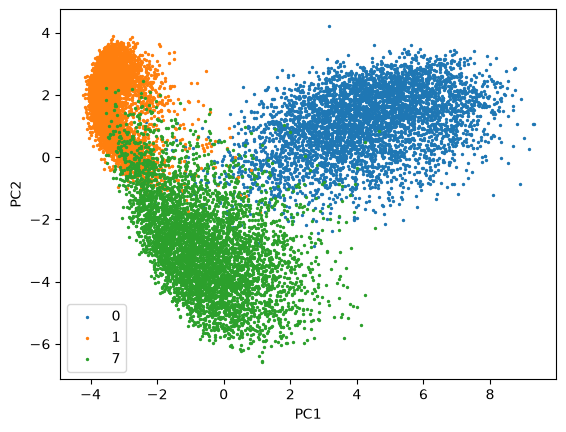

In [22]:
show_clusters(train_features, train_labels)

## 4. Models Without PCA
### GMM

In [23]:
gmm_models = []
class_priors = []

for label in class_labels:
    class_samples = train_features[train_labels == label]
    model = GMM(n_components=3, regularization=1e-3, iterations=100, convergence_tol=1e-4)
    model.fit(class_samples)
    gmm_models.append(model)
    class_priors.append(len(class_samples) / len(train_features))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.iterations:
        print("Iteration limit reached; convergence is not guaranteed.")

valid_scores = np.column_stack([m.score_samples(valid_features) for m in gmm_models])
gmm_valid_preds = class_labels[np.argmax(valid_scores + np.log(class_priors), axis=1)]

test_scores = np.column_stack([m.score_samples(test_features) for m in gmm_models])
gmm_test_preds = class_labels[np.argmax(test_scores + np.log(class_priors), axis=1)]

gmm_confusion = build_confusion_matrix(test_labels, gmm_test_preds, class_labels)

print("Validation accuracy:", np.mean(gmm_valid_preds == valid_labels))
print("Test accuracy:", np.mean(gmm_test_preds == test_labels))
print("Test confusion matrix:\n", gmm_confusion)

Class 0 EM iterations: 19
Class 1 EM iterations: 49
Class 7 EM iterations: 24
Validation accuracy: 0.9869417602507182
Test accuracy: 0.9895004772510341
Test confusion matrix:
 [[ 977    0    3]
 [  17 1117    1]
 [  10    2 1016]]


### KNN

In [24]:
knn_model = KNN(neighbors=5)
knn_model.fit(train_features, train_labels)

knn_valid_preds = knn_model.predict(valid_features)
knn_test_preds = knn_model.predict(test_features)

knn_confusion = build_confusion_matrix(test_labels, knn_test_preds, class_labels)

print("Validation accuracy:", np.mean(knn_valid_preds == valid_labels))
print("Test accuracy:", np.mean(knn_test_preds == test_labels))
print("Test confusion matrix:\n", knn_confusion)

Validation accuracy: 0.9942543745103161
Test accuracy: 0.9904549793191219
Test confusion matrix:
 [[ 976    2    2]
 [   0 1135    0]
 [   0   26 1002]]


### LDA

In [25]:
lda_model = LDA()
lda_model.fit(train_features, train_labels)

lda_valid_preds = lda_model.predict(valid_features)
lda_test_preds = lda_model.predict(test_features)

lda_confusion = build_confusion_matrix(test_labels, lda_test_preds, class_labels)

print("Validation accuracy:", np.mean(lda_valid_preds == valid_labels))
print("Test accuracy:", np.mean(lda_test_preds == test_labels))
print("Test confusion matrix:\n", lda_confusion)

Validation accuracy: 0.9845912770958475
Test accuracy: 0.9853643016226535
Test confusion matrix:
 [[ 970    2    8]
 [   1 1131    3]
 [   4   28  996]]


### SVM

In [26]:
svm_model = SVM()
svm_model.fit(train_features, train_labels)

print("One-vs-rest classifiers:", len(svm_model.models))
print("Gaussian sigma:", svm_model.width)
print("Converged:", svm_model.converged)
print("Largest KKT gap:", max(svm_model.gaps))
if not svm_model.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")

svm_valid_preds = svm_model.predict(valid_features)
svm_test_preds = svm_model.predict(test_features)

svm_confusion = build_confusion_matrix(test_labels, svm_test_preds, class_labels)

print("Validation accuracy:", np.mean(svm_valid_preds == valid_labels))
print("Test accuracy:", np.mean(svm_test_preds == test_labels))
print("Test confusion matrix:\n", svm_confusion)

One-vs-rest classifiers: 3
Gaussian sigma: 3.533045227140011
Converged: True
Largest KKT gap: 0.000994743508310636
Validation accuracy: 0.9968660224601724
Test accuracy: 0.9968183264397072
Test confusion matrix:
 [[ 977    1    2]
 [   0 1133    2]
 [   1    4 1023]]


## 5. Dimensionality Reduction (PCA)

In [33]:
num_components = 50
pca_transformer = PCA(n_components=num_components)
pca_transformer.fit(train_features)

train_features_pca = pca_transformer.transform(train_features)
valid_features_pca = pca_transformer.transform(valid_features)
test_features_pca = pca_transformer.transform(test_features)

print("Training PCA shape:", train_features_pca.shape)
print("Validation PCA shape:", valid_features_pca.shape)
print("Testing PCA shape:", test_features_pca.shape)

Training PCA shape: (15101, 50)
Validation PCA shape: (3829, 50)
Testing PCA shape: (3143, 50)


## 6. Models With PCA
### GMM with PCA

In [34]:
pca_gmm_models = []
pca_class_priors = []

for label in class_labels:
    pca_samples = train_features_pca[train_labels == label]
    pca_model = GMM(n_components=3, regularization=1e-3, iterations=100, convergence_tol=1e-4)
    pca_model.fit(pca_samples)
    pca_gmm_models.append(pca_model)
    pca_class_priors.append(len(pca_samples) / len(train_features_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.iterations:
        print("Iteration limit reached; convergence is not guaranteed.")

pca_valid_scores = np.column_stack([m.score_samples(valid_features_pca) for m in pca_gmm_models])
gmm_pca_valid_preds = class_labels[np.argmax(pca_valid_scores + np.log(pca_class_priors), axis=1)]

pca_test_scores = np.column_stack([m.score_samples(test_features_pca) for m in pca_gmm_models])
gmm_pca_test_preds = class_labels[np.argmax(pca_test_scores + np.log(pca_class_priors), axis=1)]

gmm_pca_confusion = build_confusion_matrix(test_labels, gmm_pca_test_preds, class_labels)

print("Validation accuracy:", np.mean(gmm_pca_valid_preds == valid_labels))
print("Test accuracy:", np.mean(gmm_pca_test_preds == test_labels))
print("Test confusion matrix:\n", gmm_pca_confusion)

Class 0 EM iterations: 22
Class 1 EM iterations: 45
Class 7 EM iterations: 23
Validation accuracy: 0.9947767041002873
Test accuracy: 0.9968183264397072
Test confusion matrix:
 [[ 980    0    0]
 [   0 1135    0]
 [   2    8 1018]]


### KNN with PCA

In [35]:
knn_pca_model = KNN(neighbors=5)
knn_pca_model.fit(train_features_pca, train_labels)

knn_pca_valid_preds = knn_pca_model.predict(valid_features_pca)
knn_pca_test_preds = knn_pca_model.predict(test_features_pca)

knn_pca_confusion = build_confusion_matrix(test_labels, knn_pca_test_preds, class_labels)

print("Validation accuracy:", np.mean(knn_pca_valid_preds == valid_labels))
print("Test accuracy:", np.mean(knn_pca_test_preds == test_labels))
print("Test confusion matrix:\n", knn_pca_confusion)

Validation accuracy: 0.9963436928702011
Test accuracy: 0.9914094813872096
Test confusion matrix:
 [[ 976    2    2]
 [   0 1135    0]
 [   1   22 1005]]


### LDA with PCA

In [36]:
lda_pca_model = LDA()
lda_pca_model.fit(train_features_pca, train_labels)

lda_pca_valid_preds = lda_pca_model.predict(valid_features_pca)
lda_pca_test_preds = lda_pca_model.predict(test_features_pca)

lda_pca_confusion = build_confusion_matrix(test_labels, lda_pca_test_preds, class_labels)

print("Validation accuracy:", np.mean(lda_pca_valid_preds == valid_labels))
print("Test accuracy:", np.mean(lda_pca_test_preds == test_labels))
print("Test confusion matrix:\n", lda_pca_confusion)

Validation accuracy: 0.980673805171063
Test accuracy: 0.9844097995545658
Test confusion matrix:
 [[ 972    1    7]
 [   0 1132    3]
 [   3   35  990]]


### SVM with PCA

In [37]:
svm_pca_model = SVM()
svm_pca_model.fit(train_features_pca, train_labels)

print("One-vs-rest classifiers:", len(svm_pca_model.models))
print("Gaussian sigma:", svm_pca_model.width)
print("Converged:", svm_pca_model.converged)
print("Largest KKT gap:", max(svm_pca_model.gaps))
if not svm_pca_model.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")

svm_pca_valid_preds = svm_pca_model.predict(valid_features_pca)
svm_pca_test_preds = svm_pca_model.predict(test_features_pca)

svm_pca_confusion = build_confusion_matrix(test_labels, svm_pca_test_preds, class_labels)

print("Validation accuracy:", np.mean(svm_pca_valid_preds == valid_labels))
print("Test accuracy:", np.mean(svm_pca_test_preds == test_labels))
print("Test confusion matrix:\n", svm_pca_confusion)

One-vs-rest classifiers: 3
Gaussian sigma: 3.3142123017189244
Converged: True
Largest KKT gap: 0.0009805663502675532
Validation accuracy: 0.997127187255158
Test accuracy: 0.9971364937957365
Test confusion matrix:
 [[ 977    1    2]
 [   1 1134    0]
 [   1    4 1023]]


## 7. Accuracy Comparison

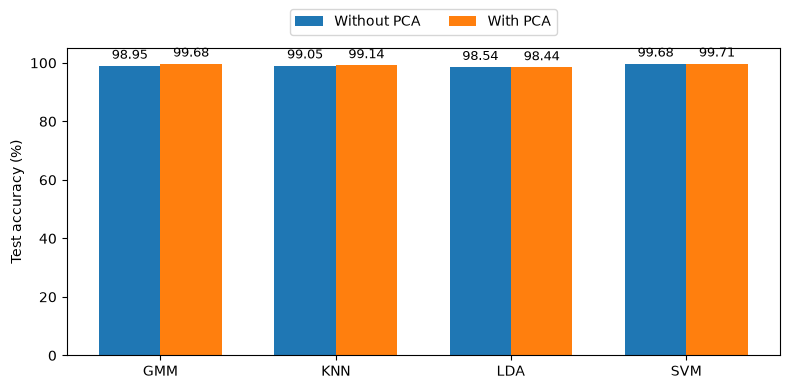

In [38]:
baseline_accuracies = [
    100 * np.trace(cm) / cm.sum()
    for cm in [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]
]
pca_accuracies = [
    100 * np.trace(cm) / cm.sum()
    for cm in [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]
]

positions = np.arange(4)
bar_width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
baseline_bars = ax.bar(positions - bar_width / 2, baseline_accuracies, bar_width, label="Without PCA")
pca_bars = ax.bar(positions + bar_width / 2, pca_accuracies, bar_width, label="With PCA")

ax.bar_label(baseline_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()